# [3차시] 데이터 전처리 연습

- 첫번째 베이스라인 모델은 머신러닝 모델을 사용하지 않고, 이전 월 고객 구매액을 계산한 후에 이를 예측값으로 사용해서 베이스라인 모델 구현했었습니다.
- 두 번째 베이스라인 모델은 이번 강의에서 배운 LightGBM 모델을 사용해서 베이스라인 모델 구현합니다.

**유의사항**
- 첫번째 베이스라인 모델에서 이전 월 고객 구매액만을 피처로 사용하는 것과 달리 두 번째 베이스라인 모델은 2009년 12월부터 예측하기를 원하는 월의 이전 월 전체 데이터를 사용합니다.
- 우리는 고객의 총 구매액이 300을 넘을지 말지를 예측하는 것인데 주어진 데이터는 개별 거래 데이터이기 때문에 데이터를 고객 기준으로 group by하고 count, sum, mean 등의 집계함수를 사용해서 피처를 생성합니다. (피처에 대한 상세한 설명은 다음 강의에서 진행합니다.)
- 2011년 12월 데이터가 없기 때문에 2011년 10월을 train 데이터, 2011년 11월을 validation 데이터로 해서 LightGBM 베이스라인 모델 validation 성능을 측정합니다.

## Function 정의

- seed_everything() : seed 고정 함수
- generate_label() : label 생성 함수
- print_score() : 평가지표 출력 함수
- feature_preprocessing() : 데이터 전처리 함수(label encoding, 결측치 처리)
- feature_engineering1() : 피처 엔지니어링 함수
- make_lgb_prediction() : LightGBM train/predict 함수
- plot_feature_importances() : LightGBM 피처 중요도 플롯 함수

## Library Import

In [1]:
# Suppress warnings
import warnings
warnings.filterwarnings('ignore')

import os, sys, gc, warnings, random
from typing import List

import datetime
import dateutil.relativedelta

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, precision_recall_curve, roc_curve
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold, GroupKFold
from sklearn.ensemble import RandomForestClassifier

import lightgbm as lgb

from tqdm.notebook import trange, tqdm

from IPython.display import display

%matplotlib inline

pd.options.display.max_rows = 10000
pd.options.display.max_columns = 1000
pd.options.display.max_colwidth = 1000

In [33]:
list = ['catboost', 'matplotlib', 'numpy', 'pandas',
       'scikit-learn', 'seaborn', 'xgboost', 'lightgbm', 'tqdm', 'notebook', 'optuna']

import importlib

for lib in list:
    try:
        module = importlib.import_module(lib)
        print(f"{lib}: {module.__version__}")
    except ImportError:
        print(f"{lib}: Not installed")

catboost: Not installed
matplotlib: 3.7.2
numpy: 1.24.3
pandas: 1.3.4
scikit-learn: Not installed
seaborn: 0.12.2
xgboost: 1.7.5
lightgbm: 4.3.0
tqdm: 4.65.0
notebook: 6.4.6
optuna: Not installed


## Fix Seed 함수 정의

In [2]:
'''
    결과의 재현성을 위해 seed 값을 설정하는 함수
'''
def seed_everything(seed=0):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

SEED = 42
seed_everything(SEED)

## 레이블 생성 함수 정의

- 레이블 생성 함수는 연월을 인자로 받아서 고객 아이디별로 총 구매액이 인자로 받는 구매액 임계값을 넘는지 여부를 바이너리 레이블로 생성하는 함수

In [3]:
TOTAL_THRES = 300

'''
    입력인자로 받는 year_month에 대해 고객 ID별로 총 구매액이
    구매액 임계값을 넘는지 여부의 binary label을 생성하는 함수
'''
def generate_label(
    df: pd.DataFrame,
    year_month: str,
    total_thres: int = TOTAL_THRES,
    print_log: bool = False
):
    df = df.copy()

    # year_month에 해당하는 label 데이터 생성
    df['year_month'] = df['order_date'].dt.strftime('%Y-%m')
    df.reset_index(drop=True, inplace=True)

    # year_month 이전 월의 고객 ID 추출
    cust = df[df['year_month']<year_month]['customer_id'].unique()
    # year_month에 해당하는 데이터 선택
    df = df[df['year_month']==year_month]

    # label 데이터프레임 생성
    label = pd.DataFrame({'customer_id':cust})
    label['year_month'] = year_month

    # year_month에 해당하는 고객 ID의 구매액의 합 계산
    grped = df.groupby(['customer_id','year_month'], as_index=False)[['total']].sum()

    # label 데이터프레임과 merge하고 구매액 임계값을 넘었는지 여부로 label 생성
    label = label.merge(grped, on=['customer_id','year_month'], how='left')
    label['total'].fillna(0.0, inplace=True)
    label['label'] = (label['total'] > total_thres).astype(int)

    # 고객 ID로 정렬
    label = label.sort_values('customer_id').reset_index(drop=True)
    if print_log: print(f'{year_month} - final label shape: {label.shape}')

    return label

## 평가지표 출력 함수 정의

In [4]:
'''
    평가지표를 출력하는 함수
'''
def print_score(label: List[float], pred: List[float], prob_thres: float = 0.5):
    print('Precision: {:.5f}'.format(precision_score(label, pred>prob_thres)))
    print('Recall: {:.5f}'.format(recall_score(label, pred>prob_thres)))
    print('F1 Score: {:.5f}'.format(f1_score(label, pred>prob_thres)))
    print('ROC AUC Score: {:.5f}'.format(roc_auc_score(label, pred)))

## 데이터 전처리 함수 정의
- 범주형 변수 레이블 인코딩
- 결측치 중위값으로 채움

In [5]:
'''
    입력인자로 받는 train, test 데이터에 대해 범주형 피쳐는 레이블 인코딩을
    진행하고 결측치에 대해서는 중위값으로 데이터 전처리를 하는 함수
'''
def feature_preprocessing(
    train: pd.DataFrame,
    test: pd.DataFrame,
    features: list,
    do_imputing=True
        ## do_imputing 매개변수를 지정하지 않으면 자동으로 누락된 값을 처리하게 된다.
        ## False로 설정한다면 데이터에 결측치가 존재해도 무시하고 해당 기능 실행

):
    x_tr = train.copy()
    x_te = test.copy()

    # 범주형 피처 이름을 저장할 변수
    cate_cols = []

    # 레이블 인코딩
    for f in features:
        if x_tr[f].dtype.name == 'object': # 데이터 타입이 object(str)이면 레이블 인코딩
            cate_cols.append(f)
            le = LabelEncoder()
            # train + test 데이터를 합쳐서 레이블 인코딩 함수에 fit
            le.fit(list(x_tr[f].values) + list(x_te[f].values))

            # train 데이터 레이블 인코딩 변환 수행
            x_tr[f] = le.transform(list(x_tr[f].values))

            # test 데이터 레이블 인코딩 변환 수행
            x_te[f] = le.transform(list(x_te[f].values))

    print('categorical feature:', cate_cols)

    if do_imputing:
        
        ## from sklearn.impute import SimpleImputer
        ## SimpleImputer는 누락된 값을 특정한 대체값으로 채우는 역할
        ## 평균값 mean, 중위값 median, 최빈값 most frequent, 직접 지정하는 'constant'
    # 중위값으로 결측치 채우기        
        imputer = SimpleImputer(strategy='median')

        x_tr[features] = imputer.fit_transform(x_tr[features])
        x_te[features] = imputer.transform(x_te[features])

    return x_tr, x_te

## 피처 엔지니어링 함수 정의
- Pandas groupby aggregation 함수를 사용한 피처 엔지니어링

Feature Engineering이란 기존 데이터를 손보아 더 나은 변수를 만드는 기법

- 데이터 스케일링 또는 정규화
- 비수치적 데이터 인코딩
- 시간 또는 엔터티별 데이터 집계
- 다른 소스의 데이터 조인 또는 다른 모델에서의 지식 이전 등 포함

다른 데이터 세트로부터 학습하는 머신러닝 알고리즘 능력을 향상하고 더 정확한 예측 수행이 목표



멀티레벨 컬럼의 예시

In [6]:
# 멀티레벨 인덱스를 가진 데이터프레임 생성
data = {
    ('2022-01-01', 'Open'): [100, 200, 150],
    ('2022-01-01', 'High'): [110, 210, 160],
    ('2022-01-01', 'Low'): [90, 190, 140],
    ('2022-01-02', 'Open'): [120, 220, 170],
    ('2022-01-02', 'High'): [130, 230, 180],
    ('2022-01-02', 'Low'): [110, 210, 160]
}

df = pd.DataFrame(data, index=['AAPL', 'GOOG', 'MSFT'])
print(df)


     2022-01-01           2022-01-02          
           Open High  Low       Open High  Low
AAPL        100  110   90        120  130  110
GOOG        200  210  190        220  230  210
MSFT        150  160  140        170  180  160


In [7]:
'''
    입력인자로 받는 year_month와 변수 prev_ym 기준으로 train, test 데이터를 생성 하고
    집계(aggregation) 함수를 사용하여 피처 엔지니어링을 하는 함수
'''
def feature_engineering1(df: pd.DataFrame, year_month: str):
    df = df.copy()

    # year_month 이전 월 계산
    d = datetime.datetime.strptime(year_month, "%Y-%m")
    prev_ym = d - dateutil.relativedelta.relativedelta(months=1)
    prev_ym = prev_ym.strftime('%Y-%m')

    # train, test 데이터 선택
    train = df[df['order_date'] < prev_ym]
    test = df[df['order_date'] < year_month]

    # train, test 레이블 데이터 생성
    train_label = generate_label(df, prev_ym)[['customer_id','year_month','label']]
    test_label = generate_label(df, year_month)[['customer_id','year_month','label']]

    # group by aggregation 함수 선언
    agg_func = ['mean','max','min','sum','count','std','skew']
        ## skew는 왜도(skewness)를 계산하는 함수로 분포의 대칭성을 나타낸다.
        ## 데이터의 왜도가 0에 가깝다면, 데이터는 대칭적이다.
        ## 양수인 경우, 분포의 오른쪽 꼬리가 더 길고 분포가 오른쪽으로 치우쳐져있다.
        ## 음수인 경우는 반대
    all_train_data = pd.DataFrame()

    for i, tr_ym in enumerate(train_label['year_month'].unique()):
        # group by aggretation 함수로 train 데이터 피처 생성
        ## enumerate() 함수는 반복 가능한 객체(리스트, 튜플, 문자열 등)를 입력 받아 인덱스와 해당 요소를 순회 하는데 사용
        ## index와 value 반환
        train_agg = train.loc[train['order_date'] < tr_ym].groupby(['customer_id']).agg(agg_func)

        # 멀티 레벨 컬럼을 사용하기 쉽게 1 레벨 컬럼명으로 변경
        new_cols = []
        for col in train_agg.columns.levels[0]:
            for stat in train_agg.columns.levels[1]:
                new_cols.append(f'{col}-{stat}')

        train_agg.columns = new_cols
        train_agg.reset_index(inplace = True)

        train_agg['year_month'] = tr_ym

        all_train_data = all_train_data.append(train_agg)

    all_train_data = train_label.merge(all_train_data, on=['customer_id', 'year_month'], how='left')
    features = all_train_data.drop(columns=['customer_id', 'label', 'year_month']).columns

    # group by aggretation 함수로 test 데이터 피처 생성
    test_agg = test.groupby(['customer_id']).agg(agg_func)
    test_agg.columns = new_cols

    test_data = test_label.merge(test_agg, on=['customer_id'], how='left')

    # train, test 데이터 전처리
    x_tr, x_te = feature_preprocessing(all_train_data, test_data, features)

    print('x_tr.shape', x_tr.shape, ', x_te.shape', x_te.shape)

    return x_tr, x_te, all_train_data['label'], features

## LightGBM train/predict 함수 정의

In [68]:
'''
    학습 데이터(train), 테스트 데이터(test)로 LightGBM 모델을
    학습 및 테스트하고 사용된 피처들의 중요도를 반환하는 함수
'''
def make_lgb_prediction(train, y, test, features, categorical_features='auto', model_params=None):
    x_train = train[features]
    x_test = test[features]

    print(x_train.shape, x_test.shape)

    # 피처 중요도를 저장할 데이터 프레임 선언
    fi = pd.DataFrame()
    fi['feature'] = features

    # LightGBM 데이터셋 선언
    dtrain = lgb.Dataset(x_train, label=y)

    # LightGBM 모델 훈련
    clf = lgb.train(
        model_params,
        dtrain,
        categorical_feature=categorical_features
    )

    # 테스트 데이터 예측
    test_preds = clf.predict(x_test)

    # 피처 중요도 저장
    fi['importance'] = clf.feature_importance()

    return test_preds, fi

## LightGBM 피처 중요도 플롯 함수 정의

In [69]:
'''
    피처 중요도 정규화(importance_normalized) 및 누적 중요도(cumulative_importance)를 계산하고
    중요도 정규화 순으로 n개의 바플롯을 그리는 함수
'''
def plot_feature_importances(df, n=20, color='blue', figsize=(12,8)):
    # 피처 중요도 순으로 내림차순 정렬
    df = df.sort_values('importance', ascending = False).reset_index(drop = True)

    # 피처 중요도 정규화 및 누적 중요도 계산
    df['importance_normalized'] = df['importance'] / df['importance'].sum()
    df['cumulative_importance'] = np.cumsum(df['importance_normalized'])

    plt.rcParams['font.size'] = 12
    plt.style.use('fivethirtyeight')
    # 피처 중요도 순으로 n개까지 바플롯으로 그리기
    df.loc[:n, :].plot.barh(y='importance_normalized',
                            x='feature', color=color,
                            edgecolor='k', figsize=figsize,
                            legend=False)

    plt.xlabel('Normalized Importance', size=18); plt.ylabel('');
    plt.title(f'Top {n} Most Important Features', size=18)
    plt.gca().invert_yaxis()

    return df

## Train 데이터 읽기
- 9개의 feature를 가진 780502개의 train data

In [70]:
data = pd.read_csv("data/input/train.csv", parse_dates=["order_date"])
print(data.shape) # data shape 확인
data.head()

(780502, 9)


,order_id,product_id,description,quantity,order_date,price,customer_id,country,total
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,11.4675,13085,United Kingdom,137.61
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,11.1375,13085,United Kingdom,133.65
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,11.1375,13085,United Kingdom,133.65
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,3.4650,13085,United Kingdom,166.32
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,2.0625,13085,United Kingdom,49.50


## Pandas info() 함수로 데이터 타입 및 null 체크

In [71]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 780502 entries, 0 to 780501
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   order_id     780502 non-null  object        
 1   product_id   780502 non-null  object        
 2   description  780502 non-null  object        
 3   quantity     780502 non-null  int64         
 4   order_date   780502 non-null  datetime64[ns]
 5   price        780502 non-null  float64       
 6   customer_id  780502 non-null  int64         
 7   country      780502 non-null  object        
 8   total        780502 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(4)
memory usage: 53.6+ MB


## Pandas isna(), sum() 함수로 null 데이터 개수 체크

In [72]:
data.isna().sum()

order_id       0
product_id     0
description    0
quantity       0
order_date     0
price          0
customer_id    0
country        0
total          0
dtype: int64

## Pandas describe() 함수에 include='all' 인자 설정으로 수치형, 범주형 데이터 기본 통계량 확인

In [73]:
data.describe(include='all')

,order_id,product_id,description,quantity,order_date,price,customer_id,country,total
count,780502,780502,780502,780502.000000,780502,780502.000000,780502.000000,780502,780502.000000
unique,43955,4645,5297,NaN,40615,NaN,NaN,41,NaN
top,576339,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,2011-11-14 15:27:00,NaN,NaN,United Kingdom,NaN
freq,542,5096,5096,NaN,543,NaN,NaN,700317,NaN
first,NaN,NaN,NaN,NaN,2009-12-01 07:45:00,NaN,NaN,NaN,NaN
last,NaN,NaN,NaN,NaN,2011-11-30 17:42:00,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,12.623307,NaN,6.140931,15313.393466,NaN,33.715373
std,NaN,NaN,NaN,143.906302,NaN,119.042266,1695.765797,NaN,274.207403
min,NaN,NaN,NaN,-74215.000000,NaN,0.000000,12346.000000,NaN,-127352.940000
25%,NaN,NaN,NaN,2.000000,NaN,2.062500,13963.000000,NaN,7.260000


## 2011년 11월 Label 데이터 생성

In [74]:
label_2011_11 = generate_label(data, '2011-11')['label']

## Label 데이터 분포 플롯

0    4534
1    1188
Name: label, dtype: int64

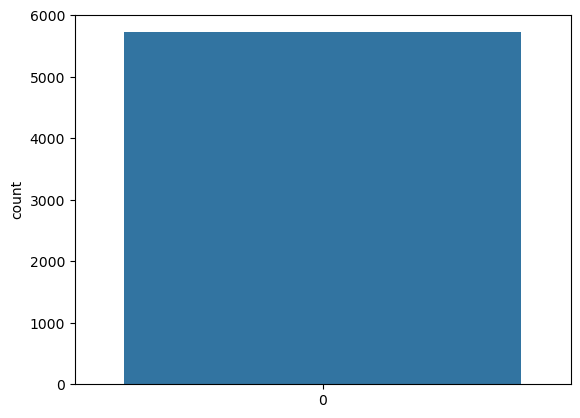

In [75]:
sns.countplot(label_2011_11);
label_2011_11.value_counts()

## LightGBM Hyperparameter 선언

In [76]:
model_params = {
    'objective': 'binary', # 이진 분류
    'boosting_type': 'gbdt',
    'metric': 'auc', # 평가 지표 설정
    'feature_fraction': 0.8, # 피처 샘플링 비율
    'bagging_fraction': 0.8, # 데이터 샘플링 비율
    'bagging_freq': 1,
    'n_estimators': 100, # 트리 개수
    'seed': SEED,
    'verbosity': 2,
    'n_jobs': -1,
}

## 2011년 11월 베이스라인 모델 예측
- Validation 성능 측정

In [77]:
train, test, y, features = feature_engineering1(data, '2011-11')
test_preds_2011_11, fi = make_lgb_prediction(train, y, test, features, model_params=model_params)
print_score(label_2011_11, test_preds_2011_11)

categorical feature: []
x_tr.shape (5501, 24) , x_te.shape (5722, 24)
(5501, 21) (5722, 21)
[LightGBM] [Info] Number of positive: 943, number of negative: 4558
[LightGBM] [Debug] Dataset::GetMultiBinFromAllFeatures: sparse rate 0.002744
[LightGBM] [Debug] init for col-wise cost 0.000171 seconds, init for row-wise cost 0.000372 seconds
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000965 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4880
[LightGBM] [Info] Number of data points in the train set: 5501, number of used features: 21
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.171423 -> initscore=-1.575573
[LightGBM] [Info] Start training from score -1.575573
[LightGBM] [Debug] Re-bagging, using 4338 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 9
[LightGBM] [Debug] Re-bagging, using 4382 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 1

[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 11
[LightGBM] [Debug] Re-bagging, using 4398 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 9
[LightGBM] [Debug] Re-bagging, using 4404 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 12
[LightGBM] [Debug] Re-bagging, using 4407 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 15
[LightGBM] [Debug] Re-bagging, using 4376 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 13
[LightGBM] [Debug] Re-bagging, using 4374 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 8
[LightGBM] [Debug] Re-bagging, using 4419 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 13
[LightGBM] [Debug] Re-bagging, using 4436 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 14
[LightGBM] [Debug] Re-bagging, using 4379 data to train
[LightGBM] [Debug] Trained

## 2011년 11월 베이스라인 모델 예측 데이터 분포

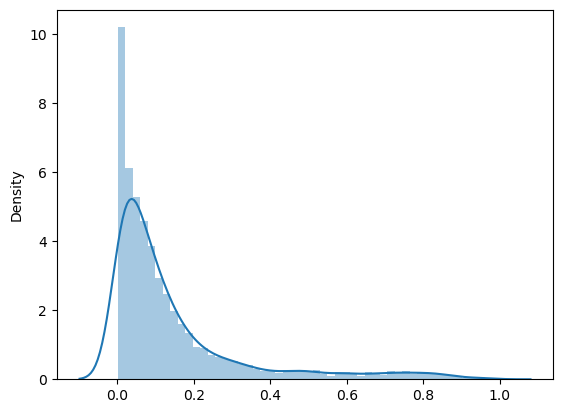

In [78]:
sns.distplot(test_preds_2011_11)
plt.show()

## 2011년 12월 베이스라인 모델 예측
- 테스트 데이터 제출

In [79]:
train, test, y, features = feature_engineering1(data, '2011-12')
test_preds, fi = make_lgb_prediction(train, y, test, features, model_params=model_params)

categorical feature: []
x_tr.shape (5722, 24) , x_te.shape (5914, 24)
(5722, 21) (5914, 21)
[LightGBM] [Info] Number of positive: 1188, number of negative: 4534
[LightGBM] [Debug] Dataset::GetMultiBinFromAllFeatures: sparse rate 0.002813
[LightGBM] [Debug] init for col-wise cost 0.000003 seconds, init for row-wise cost 0.000341 seconds
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000751 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4884
[LightGBM] [Info] Number of data points in the train set: 5722, number of used features: 21
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.207620 -> initscore=-1.339333
[LightGBM] [Info] Start training from score -1.339333
[LightGBM] [Debug] Re-bagging, using 4520 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 10
[LightGBM] [Debug] Re-bagging, using 4555 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth =

[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 13
[LightGBM] [Debug] Re-bagging, using 4555 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 10
[LightGBM] [Debug] Re-bagging, using 4584 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 12
[LightGBM] [Debug] Re-bagging, using 4553 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 15
[LightGBM] [Debug] Re-bagging, using 4544 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 11
[LightGBM] [Debug] Re-bagging, using 4610 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 12
[LightGBM] [Debug] Re-bagging, using 4596 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 12
[LightGBM] [Debug] Re-bagging, using 4551 data to train
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 10
[LightGBM] [Debug] Re-bagging, using 4623 data to train
[LightGBM] [Debug] Train

## 2011년 12월 베이스라인 모델 예측 데이터 분포

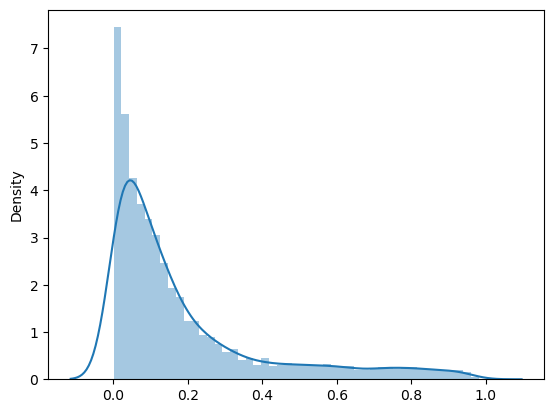

In [80]:
sns.distplot(test_preds)
plt.show()

## 피처 중요도 플롯

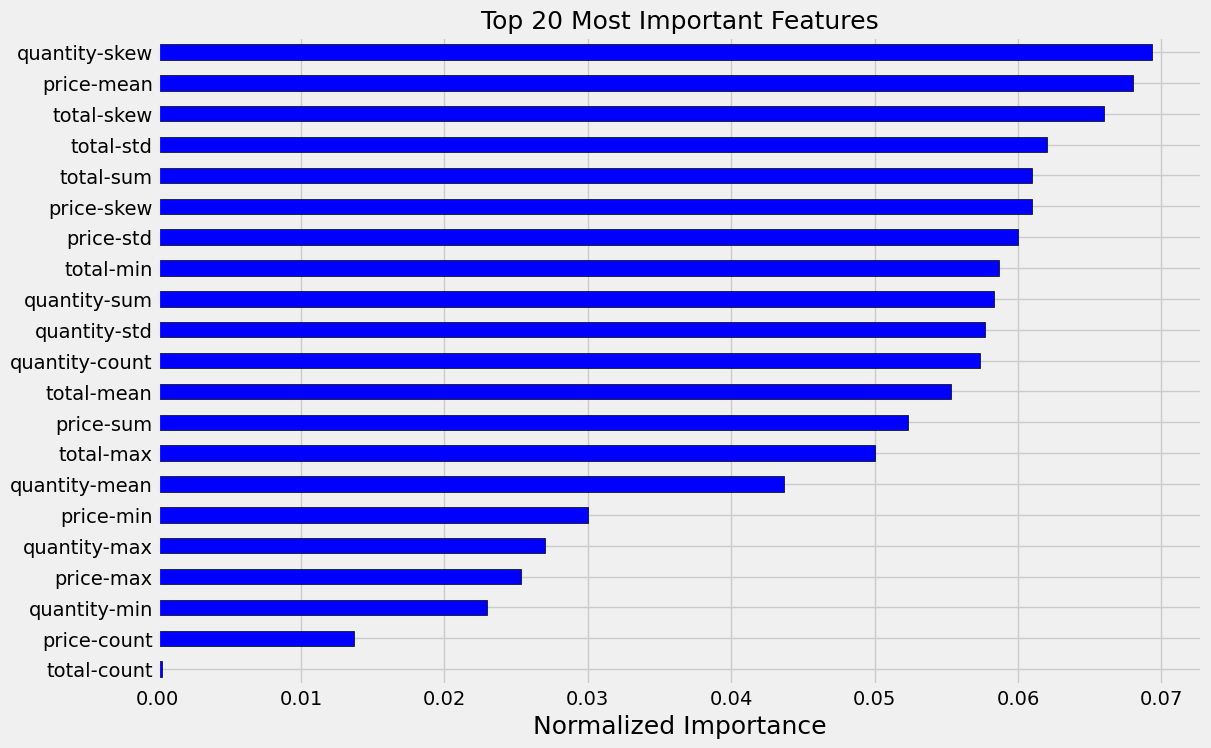

In [81]:
fi = plot_feature_importances(fi)

# 제출 파일 생성

In [83]:
output_dir = '../output'
os.makedirs(output_dir, exist_ok=True)
submission = pd.read_csv('data/input/sample_submission.csv')
submission['probability'] = test_preds
submission.to_csv(os.path.join(output_dir, 'output.csv'), index=False)

ALL RIGHTS RESERVED. (C)NAVER Connect Foundation.